# 05 — İşleme Performansı: pandas vs PySpark × CSV vs Parquet (Öğrenci 5)

**Araştırma sorusu:** Veri büyüdükçe klasik analiz yaklaşımı (tek makinede pandas + CSV) ne zaman yetersiz kalıyor?

Öğrenci 1 **okumayı** ölçtü (`io_benchmark.csv`). Bu notebook **işlemeyi** ölçer: 3 ileri analitik işlem × 3 çalışma modeli (pandas, Spark, Spark + cache) × 2 format × 5 veri boyutu + sentetik 57M + dosya düzeni kontrolü.

| İşlem | Ne yapar | Analitik tür |
|---|---|---|
| `groupby_hour` | Saate göre yolculuk sayısı, ort. mesafe, ort. ücret, toplam gelir | aggregation |
| `join_borough` | Yolculuklar ⋈ bölge tablosu (265 satır) → ilçeye göre özet | join |
| `window_top3` | Her biniş bölgesinde en yüksek tutarlı 3 yolculuk (`row_number`) | window |

Ölçümün tamamı `python -m src.benchmark_processing` (~15 dk) ve `python -m src.scale_synthetic` + `--sizes x3` / `full_rg16` ile çalışır. Bu notebook önce iki motorun aynı sonucu verdiğini canlı gösterir, sonra kayıtlı ölçümleri yorumlar.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display
from src import config
from src import benchmark_processing as bp
from src import plots_processing as pp
from src.build_sizes import target_path
pd.set_option("display.width", 160)

## 1. Aynı işlem, iki motor (canlı, 1M kayıt, Parquet)

İki motor aynı sonucu vermiyorsa hız karşılaştırması anlamsızdır. Benchmark her ölçümde satır sayısı ve checksum kaydeder; burada üç işlemi elle çalıştırıp sonuçları yan yana koyuyoruz.

In [2]:
from src.spark_session import get_spark

path = target_path(config.PROCESSED_DIR, "1m", "parquet_snappy")
pdf = bp.pandas_load(path)
zones = bp.pandas_zones()

spark = get_spark(app_name="s5-notebook")
schema = spark.read.parquet(str(path)).schema
sdf = bp.spark_frame(spark, path, "parquet_snappy", schema)
s_zones = bp.spark_zones(spark)

rows = []
for op in bp.OPERATIONS:
    p_fn, col = bp.pandas_ops(zones)[op]
    s_fn, _ = bp.spark_ops(s_zones)[op]
    p = bp.checksum(p_fn(pdf), col)
    s = bp.checksum(s_fn(sdf).toPandas(), col)
    rows.append({"işlem": op, "pandas satır": p[0], "Spark satır": s[0],
                 "pandas checksum": round(p[1], 2), "Spark checksum": round(s[1], 2)})
spark.stop()
pd.DataFrame(rows)

,işlem,pandas satır,Spark satır,pandas checksum,Spark checksum
0,groupby_hour,24,24,1000051.00,1000051.00
1,join_borough,8,8,1000051.00,1000051.00
2,window_top3,762,762,125164.42,125164.42


In [3]:
# Örnek çıktı: ilçeye göre özet (join)
bp.pandas_join_borough(pdf, zones).sort_values("trips", ascending=False)

,Borough,trips,avg_total
3,Manhattan,859521,26.010983
5,Queens,88433,64.358566
1,Brooklyn,40506,36.049442
0,Bronx,9757,37.510662
7,Unknown,1173,32.550494
4,N/A,419,102.254654
6,Staten Island,123,46.817398
2,EWR,119,96.841429


## 2. Kayıtlı ölçümler ve tutarlılık

In [4]:
summary_all = pd.read_csv(config.RESULTS_DIR / bp.SUMMARY_FILE)
summary = pp.main_curves(summary_all)  # dosya düzeni kopyası (19M ile aynı satır sayısı) hariç
print("Tutarsızlık:", bp.check_consistency(summary) or "yok — her boyutta tüm motor × format kombinasyonları aynı sonucu verdi")
pivot = summary.pivot_table(index=["op", "engine", "format"], columns="size", values="seconds_mean")
pivot[["100k", "1m", "5m", "10m", "full"]].round(3)

Tutarsızlık: yok — her boyutta tüm motor × format kombinasyonları aynı sonucu verdi


size                                      100k     1m     5m     10m    full
op           engine      format                                             
groupby_hour pandas      csv             0.007  0.039  0.192   0.369   0.697
                         parquet_snappy  0.007  0.036  0.186   0.353   0.697
             spark       csv             0.306  0.754  1.624   2.880   5.862
                         parquet_snappy  0.242  0.312  0.641   0.736   0.912
             spark_cache csv             0.568  0.526  0.546   0.604   0.565
                         parquet_snappy  0.500  0.511  0.555   0.574   0.692
join_borough pandas      csv             0.014  0.110  0.530   1.050   1.972
                         parquet_snappy  0.016  0.112  0.541   1.079   2.125
             spark       csv             0.238  0.516  1.111   1.909   4.205
                         parquet_snappy  0.244  0.297  0.509   0.573   0.708
             spark_cache csv             0.494  0.486  0.502   0.570   0.470
                         parquet_snappy  0.469  0.497  0.472   0.532   0.607
load         pandas      csv             0.130  1.092  5.364  10.280  18.818
                         parquet_snappy  0.015  0.028  0.094   0.170   0.367
             spark_cache csv             0.835  1.684  3.816   5.319  10.501
                         parquet_snappy  0.848  1.884  7.237   9.036   8.931
startup      spark       csv             5.695  5.589  5.663   5.562   5.478
                         parquet_snappy  5.484  5.557  5.492   5.518   5.813
             spark_cache csv             7.324  6.988  6.811   6.888   6.854
                         parquet_snappy  7.190  7.203  7.181   6.813   5.697
window_top3  pandas      csv             0.009  0.101  0.493   1.032   2.074
                         parquet_snappy  0.008  0.096  0.486   1.006   2.089
             spark       csv             0.573  2.469  3.566   4.764   6.623
                         parquet_snappy  0.483  1.058  3.920   5.059   6.095
             spark_cache csv             2.047  2.457  2.564   2.872   3.343
                         parquet_snappy  1.996  2.279  2.495   2.854   3.334

In [5]:
# Ölçüm kararlılığı: varyasyon katsayısı (std / ortalama), işlemler için
ops = summary[summary["op"].isin(bp.OPERATIONS)].copy()
ops["cv_%"] = (100 * ops["seconds_std"] / ops["seconds_mean"]).round(1)
ops.groupby(["engine", "format"])["cv_%"].describe()[["mean", "50%", "max"]]

mean   50%   max
engine      format                              
pandas      csv             2.288889  1.30  10.8
            parquet_snappy  6.172222  2.95  31.4
spark       csv             5.226667  5.00  15.8
            parquet_snappy  5.893333  5.80  12.5
spark_cache csv             5.577778  5.75  10.6
            parquet_snappy  4.883333  4.25  12.7

## 3. İşlem süresi

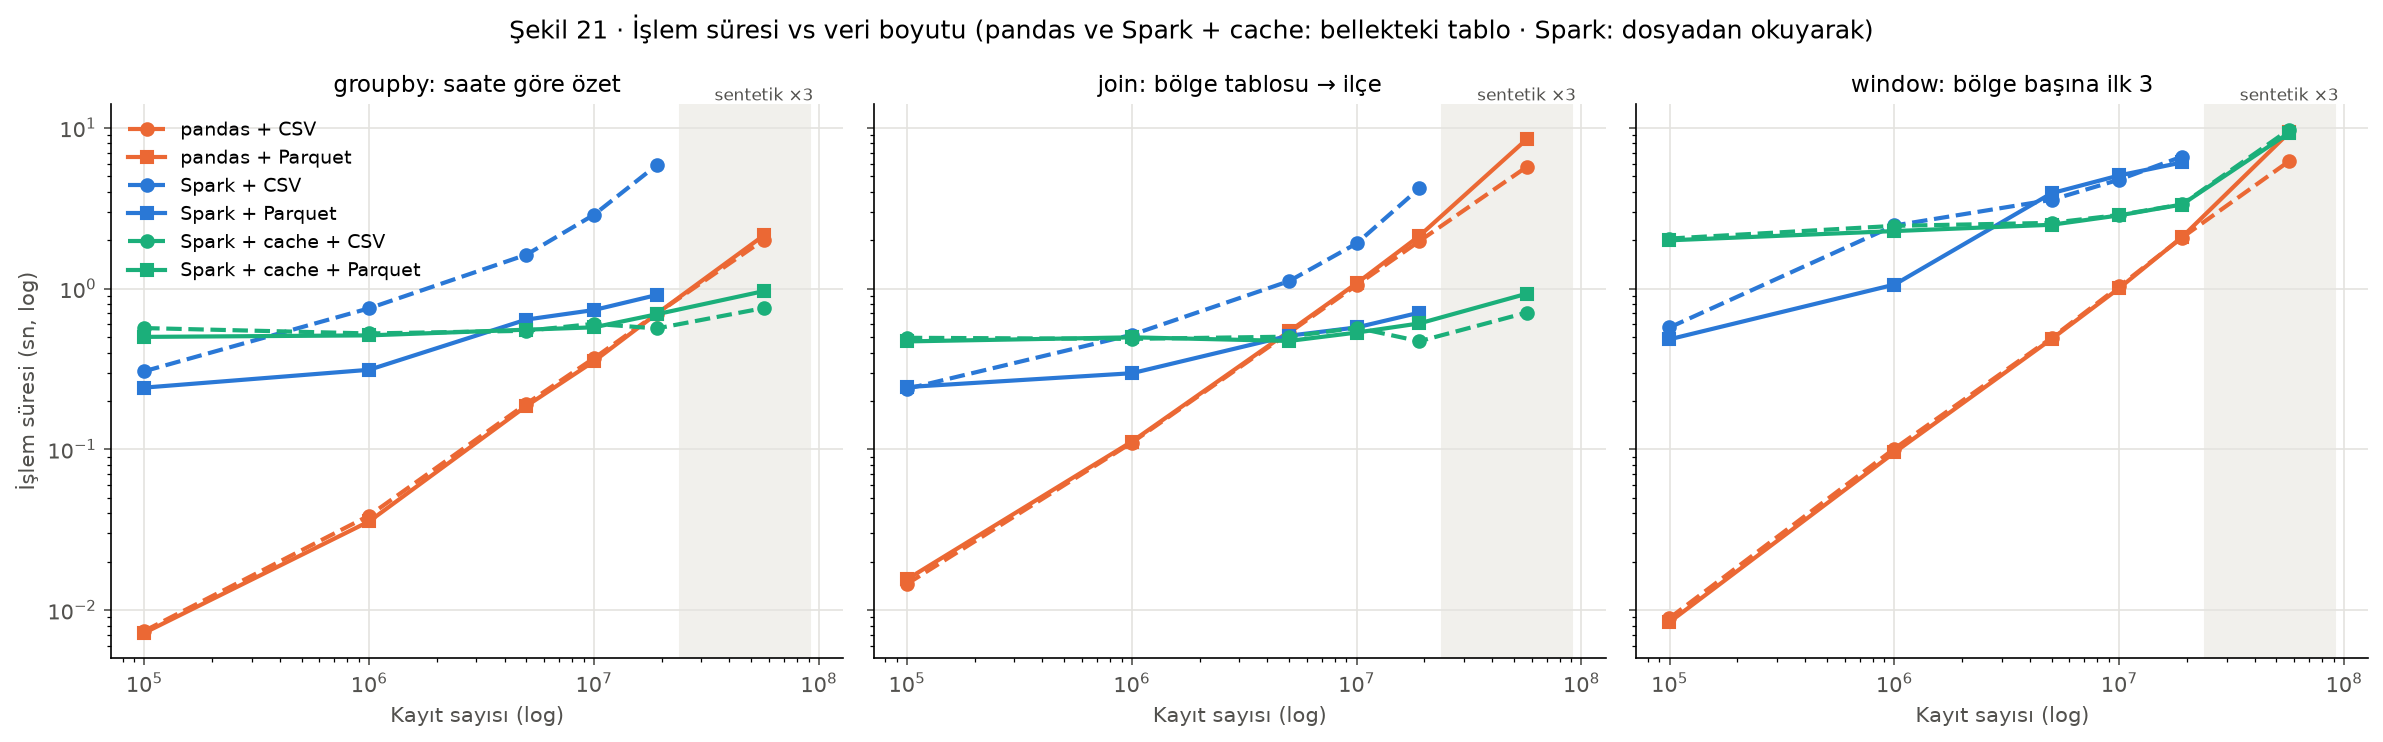

,csv,parquet_snappy
groupby_hour,—,—
join_borough,—,4.5M
window_top3,—,—


In [6]:
display(Image(filename=str(config.FIGURES_DIR / "21_s5_op_time.png")))
cross = {op: {f: pp.crossover_rows(summary[summary.op == op], f, "seconds_mean") for f in pp.FORMAT_STYLE} for op in bp.OPERATIONS}
pd.DataFrame(cross).T.map(lambda v: "—" if pd.isna(v) else f"{v/1e6:.1f}M")

Tablo: Spark'ın işlem bazında pandas'ı geçtiği kayıt sayısı ("—" = 19M'e kadar geçmiyor).

In [7]:
# Ölçeklenme: 100K → 19M (190× veri) süre artış katı
grow = summary[summary["op"].isin(bp.OPERATIONS)].pivot_table(index=["op", "engine", "format"], columns="size", values="seconds_mean")
(grow["full"] / grow["100k"]).round(1).rename("süre artışı (×)").to_frame()

süre artışı (×)
op           engine      format                         
groupby_hour pandas      csv                        94.2
                         parquet_snappy             96.8
             spark       csv                        19.2
                         parquet_snappy              3.8
             spark_cache csv                         1.0
                         parquet_snappy              1.4
join_borough pandas      csv                       136.0
                         parquet_snappy            137.1
             spark       csv                        17.7
                         parquet_snappy              2.9
             spark_cache csv                         1.0
                         parquet_snappy              1.3
window_top3  pandas      csv                       233.0
                         parquet_snappy            248.7
             spark       csv                        11.6
                         parquet_snappy             12.6
             spark_cache csv                         1.6
                         parquet_snappy              1.7

## 4. Uçtan uca süre ve bellek

rows                        99839     1000051   4997943   9996122   18999282  56997846
engine      format                                                                    
pandas      csv                 0.16      1.34      6.58     12.73     23.56     70.75
            parquet_snappy      0.05      0.27      1.31      2.61      5.28     21.40
spark       csv                 6.81      9.33     11.96     15.11     22.17       NaN
            parquet_snappy      6.45      7.23     10.56     11.89     13.53       NaN
spark_cache csv                11.27     12.14     14.24     16.25     21.73     42.70
            parquet_snappy     11.00     12.38     17.94     19.81     19.26     36.79

csv: Spark uçtan uca öne geçer → ≈ 16.1M kayıt
parquet_snappy: Spark uçtan uca öne geçer → 19M'e kadar geçmiyor


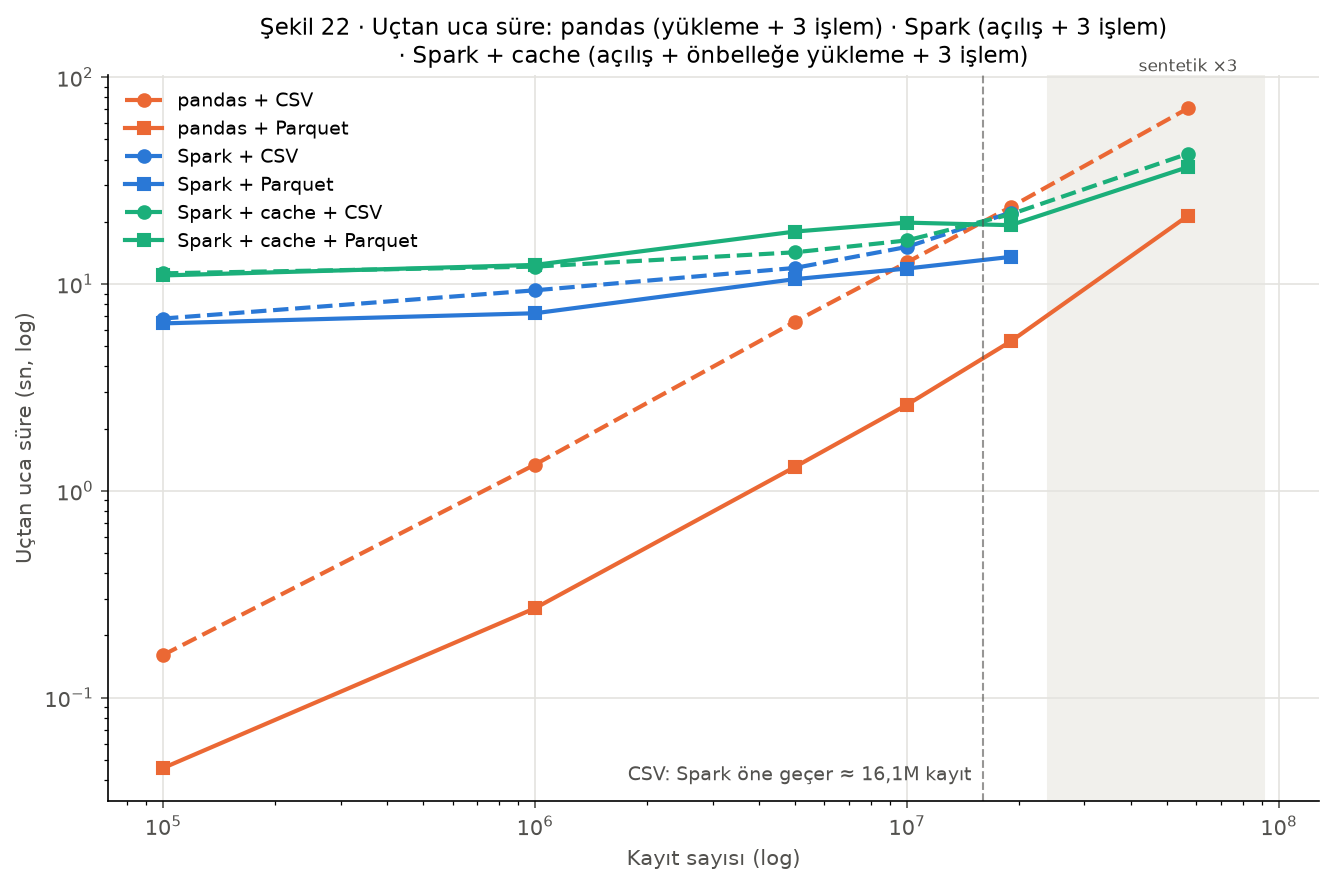

In [8]:
e2e = bp.end_to_end(summary)
display(e2e.pivot_table(index=["engine", "format"], columns="rows", values="total_s").round(2))
for f in pp.FORMAT_STYLE:
    x = pp.crossover_rows(e2e, f)
    print(f"{f}: Spark uçtan uca öne geçer →", "19M'e kadar geçmiyor" if x is None else f"≈ {x/1e6:.1f}M kayıt")
display(Image(filename=str(config.FIGURES_DIR / "22_s5_end_to_end.png")))

rows                        99839     1000051   4997943   9996122   18999282  56997846
engine      format                                                                    
pandas      csv                111.0     228.0     723.0    1273.0    2721.0    7896.0
            parquet_snappy     123.0     268.0    1318.0    2075.0    3147.0    9067.0
spark       csv                968.0    2254.0    2514.0    3280.0    4940.0       NaN
            parquet_snappy     800.0    1073.0    2054.0    2692.0    4205.0       NaN
spark_cache csv               1317.0    2349.0    3166.0    4223.0    6448.0    6922.0
            parquet_snappy    1902.0    1925.0    2362.0    3749.0    5700.0    6821.0

pandas + csv: 0.141 KB/kayıt → 236M kayıtta RAM dolar (doğrusal ekstrapolasyon)
pandas + parquet_snappy: 0.158 KB/kayıt → 210M kayıtta RAM dolar (doğrusal ekstrapolasyon)


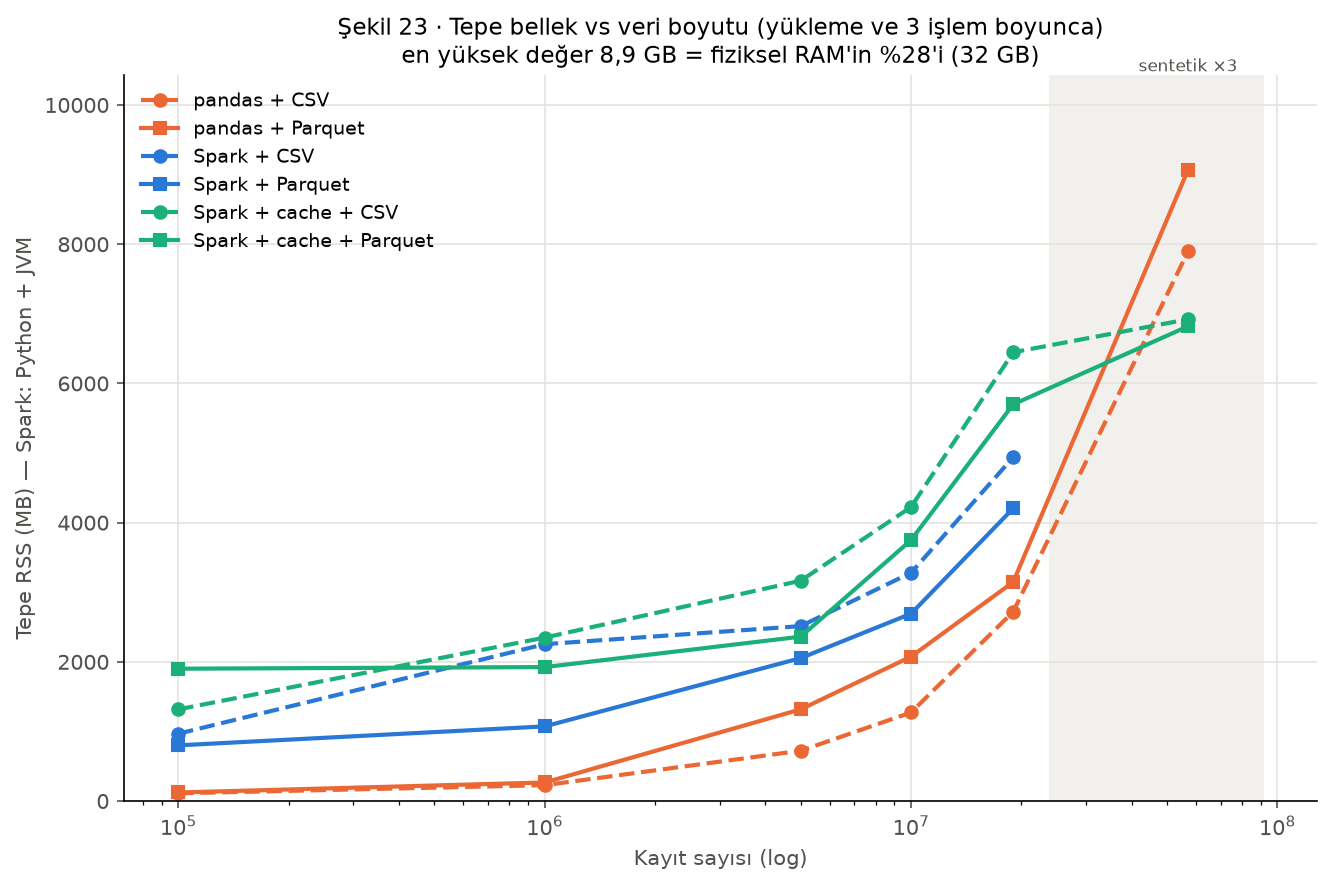

In [9]:
display(e2e.pivot_table(index=["engine", "format"], columns="rows", values="peak_rss_mb").round(0))
slopes = pp.memory_per_row_kb(summary)
import psutil
ram_mb = psutil.virtual_memory().total / 1024**2
for f, kb in slopes.items():
    print(f"pandas + {f}: {kb:.3f} KB/kayıt → {ram_mb / (kb / 1024) / 1e6:.0f}M kayıtta RAM dolar (doğrusal ekstrapolasyon)")
display(Image(filename=str(config.FIGURES_DIR / "23_s5_memory.png")))

## 4b. Ek deneyler: önbellek, sentetik 57M, dosya düzeni

In [10]:
# Spark + cache: önbelleğe alma (load) ve önbellekten işlemler
cache = summary[summary["engine"] == "spark_cache"]
display(cache.pivot_table(index=["format", "op"], columns="size", values="seconds_mean")
        [["100k", "1m", "5m", "10m", "full", "x3"]].round(2))
r = pd.read_csv(config.RESULTS_DIR / bp.RAW_FILE)
st = r[(r["op"] == "startup") & (r["status"] == "ok")]
display(st.groupby("engine")["seconds"].agg(["count", "mean", "std", "min", "max"]).round(2))

size                         100k    1m    5m   10m   full     x3
format         op                                                
csv            groupby_hour  0.57  0.53  0.55  0.60   0.56   0.76
               join_borough  0.49  0.49  0.50  0.57   0.47   0.71
               load          0.84  1.68  3.82  5.32  10.50  25.86
               startup       7.32  6.99  6.81  6.89   6.85   5.62
               window_top3   2.05  2.46  2.56  2.87   3.34   9.76
parquet_snappy groupby_hour  0.50  0.51  0.55  0.57   0.69   0.96
               join_borough  0.47  0.50  0.47  0.53   0.61   0.93
               load          0.85  1.88  7.24  9.04   8.93  17.41
               startup       7.19  7.20  7.18  6.81   5.70   8.16
               window_top3   2.00  2.28  2.50  2.85   3.33   9.32

,count,mean,std,min,max
engine,,,,,
spark,11,5.62,0.16,5.48,5.98
spark_cache,13,6.82,0.71,5.62,8.16


,size,factor,format,rows,mb,source_mb,size_ratio
0,x3,3,csv,56997846,5722.47,1907.49,3.000
1,x3,3,parquet_snappy,56997846,1144.92,381.74,2.999


peak_rss_mb         total_s      
size                              full      x3    full    x3
engine      format                                          
pandas      csv                 2720.6  7895.9    23.6  70.7
            parquet_snappy      3146.7  9066.8     5.3  21.4
spark       csv                 4939.9     NaN    22.2   NaN
            parquet_snappy      4205.3     NaN    13.5   NaN
spark_cache csv                 6447.6  6921.7    21.7  42.7
            parquet_snappy      5699.6  6820.7    19.3  36.8

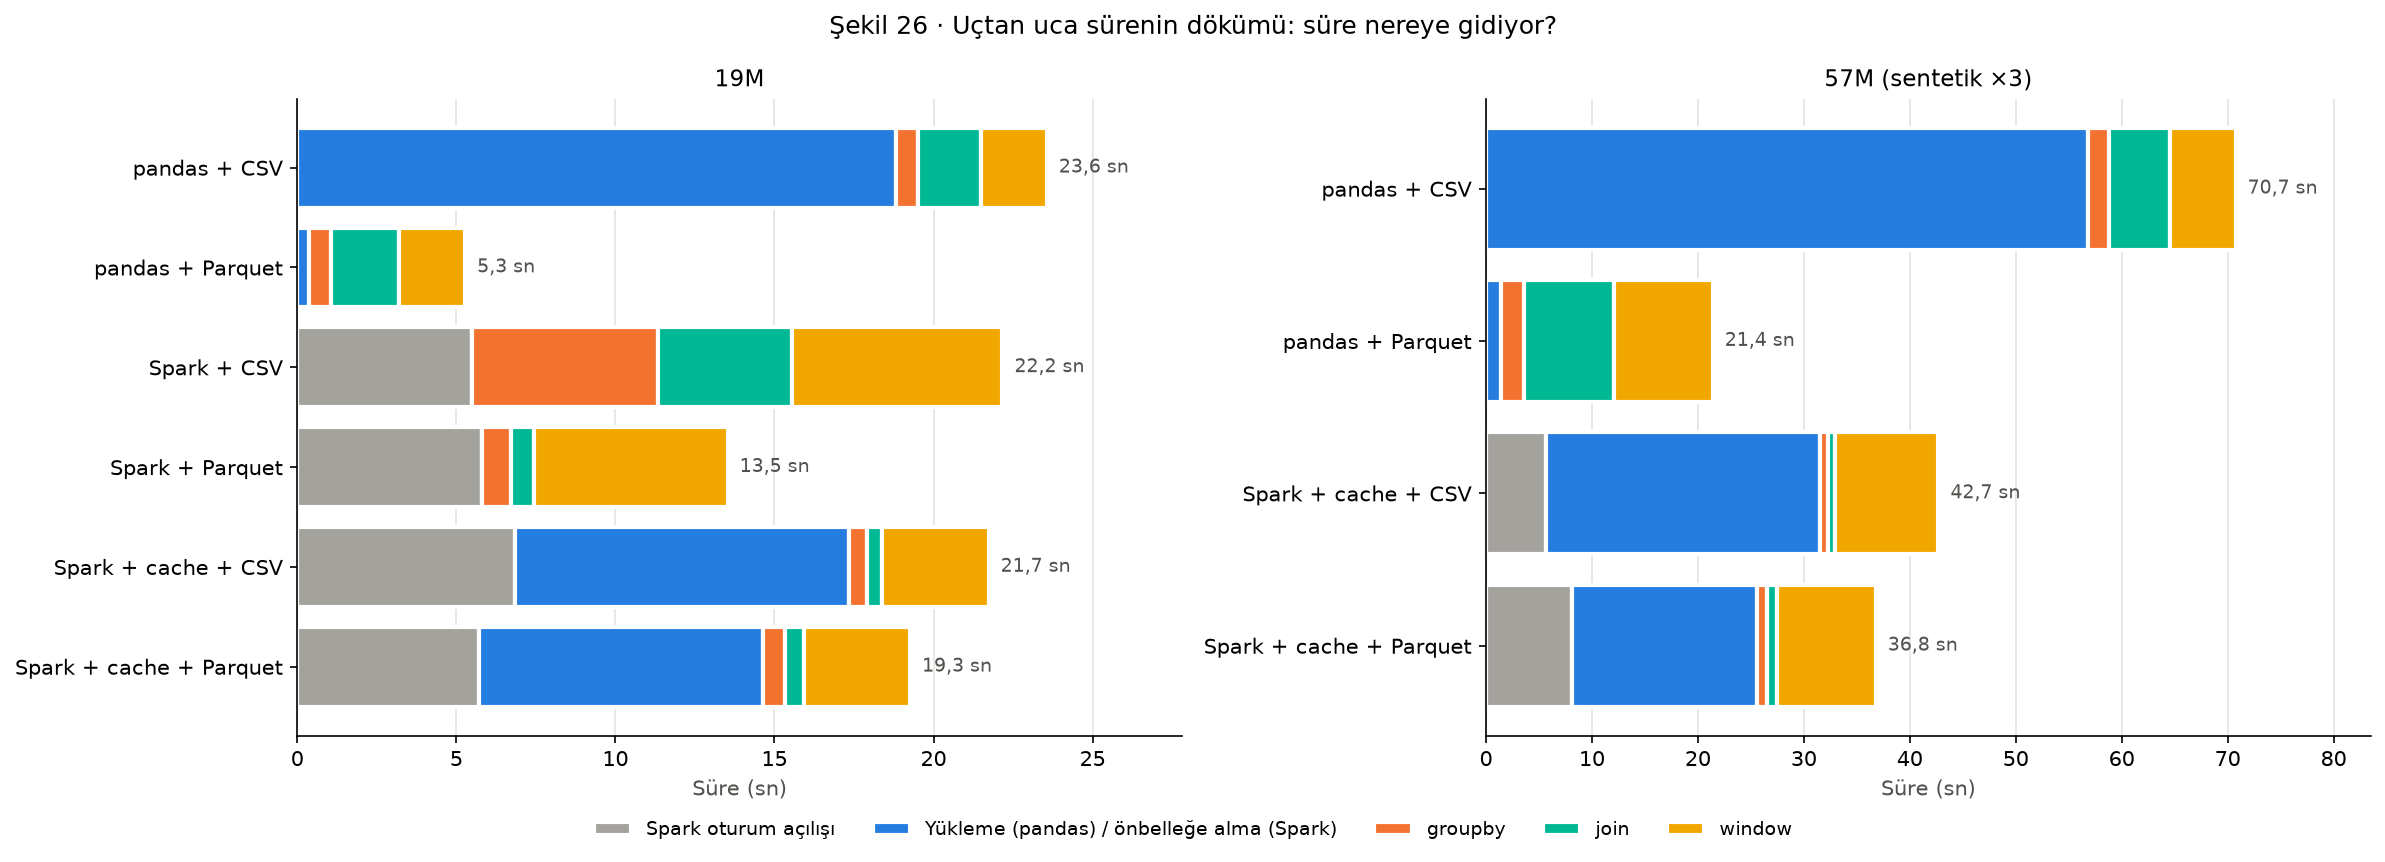

In [11]:
# Sentetik 57M (19M × 3): dosya boyutu oranı ve uçtan uca süre
display(pd.read_csv(config.RESULTS_DIR / "s5_synthetic_manifest.csv"))
display(e2e[e2e["size"].isin(["full", "x3"])].pivot_table(index=["engine", "format"], columns="size",
        values=["total_s", "peak_rss_mb"]).round(1))
display(Image(filename=str(config.FIGURES_DIR / "26_s5_time_breakdown.png")))

In [12]:
# Dosya düzeni: aynı 19M satır, 3 vs 23 row group
lay = summary_all[summary_all["size"].isin(["full", "full_rg16"]) & (summary_all["format"] == "parquet_snappy")]
lay.pivot_table(index=["engine", "op"], columns="size", values="seconds_mean").round(3)

size                       full  full_rg16
engine      op                            
pandas      groupby_hour  0.697      0.685
            join_borough  2.125      2.040
            load          0.367      0.250
            window_top3   2.089      2.078
spark       groupby_hour  0.912      0.845
            join_borough  0.708      0.638
            startup       5.813      5.982
            window_top3   6.095      3.847
spark_cache groupby_hour  0.692      0.553
            join_borough  0.607      0.474
            load          8.931      5.216
            startup       5.697      5.943
            window_top3   3.334      3.346

## 5. Yorum — neden böyle?

- **Sabit maliyet ile doğrusal maliyet.** Spark'ın oturum açılışı ~5,5 sn, işlem başına planlama + görev başlatma ~0,25 sn sabit. pandas'ta sabit maliyet yok ama süre kayıtla doğrusal artıyor (tek çekirdek). Veri 190× büyürken pandas groupby 100×, Spark + Parquet groupby 3,8× yavaşlıyor. Küçük veride pandas, büyük veride Spark avantajlı. Kesişim noktası işleme göre değişiyor.
- **Format, motordan daha belirleyici.** Spark tembel çalışıyor ve her işlemde dosyayı yeniden okuyor. CSV her seferinde tümüyle parse ediliyor (groupby 19M: CSV 5,9 sn vs Parquet 0,9 sn). pandas CSV maliyetini bir kez, yüklemede ödüyor ama bu maliyet büyük: 18,8 sn (~1M kayıt/sn). Parquet'ten yükleme 0,37 sn.
- **join: Spark kazanıyor.** Broadcast hash join + kısmi toplama 20 iş parçacığında tek aşamada çalışıyor ve birleşik tabloyu hiç oluşturmuyor. pandas `merge` 19M satırlık bir kopya oluşturup sonra grupluyor.
- **window: pandas kazanıyor.** `partitionBy` tüm verinin shuffle edilmesini (diske yaz + oku) ve her bölümde sıralamayı gerektiriyor; en yoğun bölge verinin %4,7'sini tek göreve yüklüyor. pandas tek bir vektörel sıralama yapıyor. Farkın yarısından fazlası dosya düzeninden: 19M Parquet 3 row group → 3 görevle okuma; 23 row group'la Spark window 6,1 → 3,85 sn (pandas'a göre fark 4,0 → 1,8 sn).
- **Önbellek:** önbellekli Spark 19M'de groupby/join'de pandas'tan hızlı (join 0,47 vs 1,97 sn), ama Parquet'ten önbelleğe alma 8,9 sn (pandas yüklemesi 0,37 sn). Tek seferlik iş yükünde kâra geçmiyor.
- **Sentetik 57M:** pandas + Parquet hâlâ en hızlı (21,4 sn vs 36,8 sn) ama 3× veriye 4× süre; join'de Spark 9× önde. pandas belleği 9,1 GB ile ilk kez Spark'ı (6,8 GB) geçti ve doğrusal eğimi doğruladı.
- **Bellek.** Spark'ın JVM tabanı ~0,5 GB ve window shuffle'ı 19M'de 4–5 GB'a çıkıyor. pandas 19M'de 2,7–3,1 GB kullanıyor ve kayıtla doğrusal artıyor.

## 6. Araştırma sorusuna cevap

1. **pandas + CSV, ~16M kayıtta Spark + CSV'nin, ~9M kayıtta Spark + Parquet'in gerisine düşüyor.** Darboğaz tek çekirdekli CSV parse. 57M'de pandas + CSV 70,8 sn, önbellekli Spark + CSV 42,7 sn.
2. **Formatı değiştirmek (CSV → Parquet) motoru değiştirmekten daha büyük kazanç sağlıyor.** pandas + Parquet 57M'de bile en hızlı seçenek (19M: 5,3 sn vs 13,5 sn; 57M: 21,4 sn vs 36,8 sn), ama aradaki fark kapanıyor.
3. **"Yetersizlik" işleme bağlı.** join'de Spark 4,5M'den itibaren önde (57M'de 9×); window'da 19M'de 3× geride (ama yarısına yakını dosya düzeninden), 57M'de önbellekli Spark ile başa baş.
4. **Klasik yaklaşımın sert sınırı bellek.** 57M'de pandas 9,1 GB ile Spark'ı geçti; bu makinede 6 kolonla ~200M, tüm kolonlarla ~65M kayıtta RAM dolar. Bu noktadan sonra Spark (diske taşma, dağıtım) zorunlu hale gelir.

**Sınırlamalar:** Tek makine (`local[*]`). 57M sentetik (satırlar 3 kez tekrarlı). Spark oturum açılışı iki motorda ~1,2 sn farklı ölçüldü (aynı kod, farklı ölçüm oturumu). 200M bellek sınırı ekstrapolasyon (eğim 57M'de doğrulandı). Sıcak işletim sistemi önbelleği. S1'in okuma ölçümleri farklı bir makinede alındı.